# 05. Deep learning (LSTM) + data mining (k-means, PCA, factor analysis)
This notebookd demonstrates various deep learning and data mining techniques.  

K-means finds groups of similar SKUs, while factor analysis helps explain the underlying patterns in their features.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import datetime as dt
from sklearn.linear_model import LinearRegression

from pathlib import Path
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

project_dir = Path.cwd()
data_dir = project_dir / 'Raw Data'
results_dict = {}

# Get data

In [2]:
# load single-store sales data
sales_long = pd.read_csv(
    data_dir / 'sales_long.csv',
    parse_dates=['date'],
    low_memory=False
)

# recall the level of this dataset
# i.e. a single store with many items over many dates
sales_long.groupby(['store_id','date','cat_id'])[['item_id']].nunique().head()

item_id
store_id date       cat_id            
CA_1     2011-01-29 FOODS         1437
                    HOBBIES        565
                    HOUSEHOLD     1047
         2011-01-30 FOODS         1437
                    HOBBIES        565

# Deep learning
LSTM = Long Short-Term Memory.  
It is a specialized type of Recurrent Neural Network (RNN) used in deep learning to process and predict sequential data.

## Prep

2026-10-25 16:44:22.828386: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


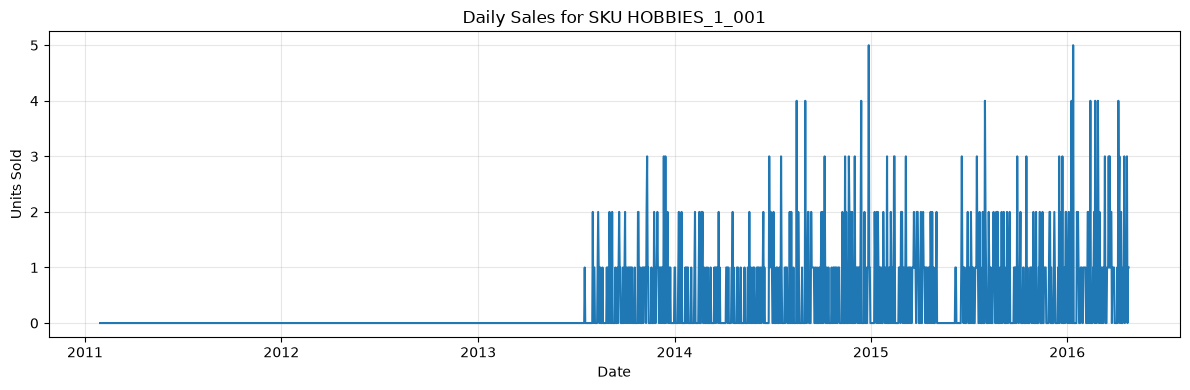

In [3]:
import tensorflow as tf

# select a single sku for this example
item_id = sales_long['item_id'].iloc[0]

sku_data = (
    sales_long.loc[sales_long['item_id'] == item_id, ['date', 'units_sold']]
    .sort_values('date')
    .reset_index(drop=True)
)

# Plot the historical sales series.
plt.figure(figsize=(12, 4))
plt.plot(sku_data['date'], sku_data['units_sold'])
plt.title(f'Daily Sales for SKU {item_id}')
plt.xlabel('Date')
plt.ylabel('Units Sold')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Scale

In [4]:
from sklearn.preprocessing import MinMaxScaler

# reserve the final 20% of dates for testing
sales = sku_data['units_sold'].to_numpy(dtype=np.float32)
split_idx = int(len(sales) * 0.8)

# fit the scaler only on training data to avoid test-data leakage
scaler = MinMaxScaler()
scaler.fit(sales[:split_idx].reshape(-1, 1))

# scale all observations using training-period parameters
sales_scaled = scaler.transform(sales.reshape(-1, 1)).flatten()

## Create X_train

In [5]:
# we need to turn one long sales history into many smaller training examples that an LSTM can learn from

# set the number of previous days used to predict the next day
lookback = 28

def create_sequences(values, lookback):
    # create empty lists to store input sequences and their targets
    X, y = [], []

    # move through the sales data starting after the first lookback days
    for i in range(lookback, len(values)):
        # store the previous 28 days as the input sequence
        X.append(values[i - lookback:i])

        # store the following day as the target to predict
        y.append(values[i])

    # convert the lists into numpy arrays for model training
    return np.array(X), np.array(y)

# create input sequences and next-day targets from the scaled sales data
X, y = create_sequences(sales_scaled, lookback)

# identify the date index each sequence is trying to predict
target_indices = np.arange(lookback, len(sales))

# mark sequences whose target dates fall before the training cutoff
train_mask = target_indices < split_idx

# mark sequences whose target dates fall on or after the testing cutoff
test_mask = target_indices >= split_idx

# separate the input sequences and targets into training and testing sets
X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

# reshape inputs into samples, time steps, and features for the lstm
# each sample has 28 time steps and one feature, daily sales
X_train = X_train.reshape(X_train.shape[0], lookback, 1)
X_test = X_test.reshape(X_test.shape[0], lookback, 1)

# display the number of sequences, time steps, and features in each set
print("Training sequences:", X_train.shape)
print("Testing sequences:", X_test.shape)

Training sequences: (1502, 28, 1)
Testing sequences: (383, 28, 1)


## Build the model

In [6]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

# create a sequential model where data flows through each layer in order
model = Sequential([
    # define the input shape as 28 days with one feature per day
    Input(shape=(lookback, 1)),

    # learn patterns and relationships across the sequence of daily sales
    # the 32 means the layer has 32 LSTM units, which learn different internal representations of the sequence
    LSTM(32),

    # convert the learned patterns into a single next-day sales prediction
    # this is the output layer
    # it takes the representation produced by the LSTM and turns it into one numerical prediction
    Dense(1)
])

# configure the model to minimize squared prediction errors during training
# optimizer='adam' selects the algorithm that adjusts the model's internal weights to improve its predictions
# loss='mse' tells the model how to measure prediction error during training
model.compile(optimizer='adam', loss='mse')

# stop training if validation performance stops improving
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

# train the model using historical sequences and their next-day targets
history = model.fit(
    X_train,
    y_train,
    # use the final 20% of training sequences to monitor validation performance
    validation_split=0.2,
    # preserve chronological order rather than shuffling the sequences
    shuffle=False,
    # allow up to 50 passes through the training data
    epochs=50,
    # process 32 sequences at a time before updating model weights
    batch_size=32,
    # stop early and restore the best-performing model weights
    callbacks=[early_stopping],
    # display training progress for each epoch
    verbose=1
)

Epoch 1/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.0055 - val_loss: 0.0343
Epoch 2/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0064 - val_loss: 0.0360
Epoch 3/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0057 - val_loss: 0.0362
Epoch 4/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0052 - val_loss: 0.0362
Epoch 5/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0050 - val_loss: 0.0358
Epoch 6/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0050 - val_loss: 0.0354


## Predict over test data

sku: HOBBIES_1_001
test mae: 0.7221 units per day


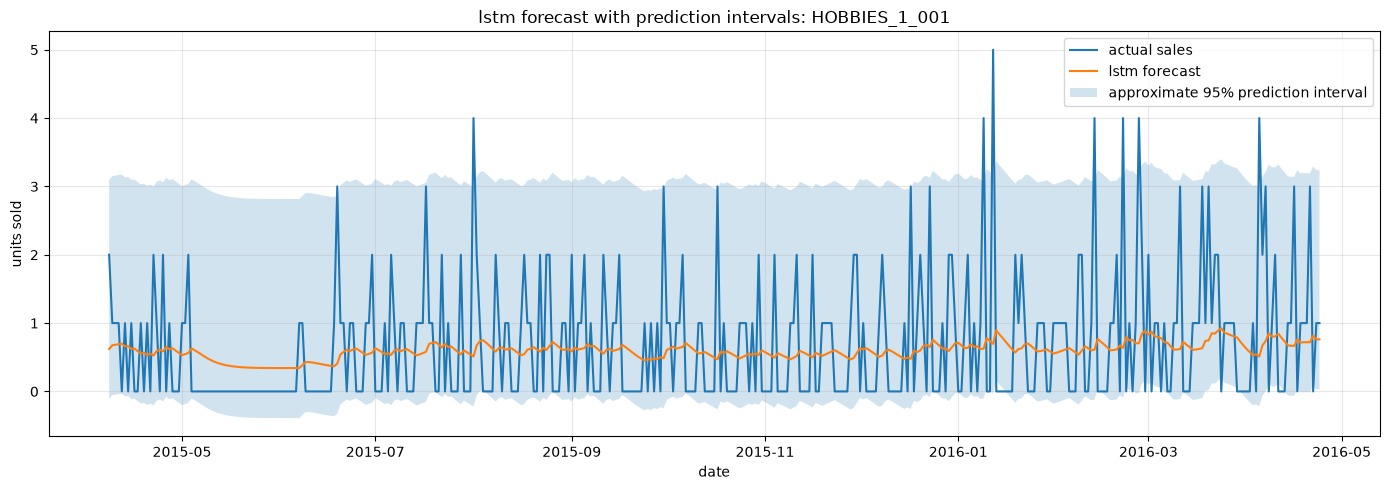

In [7]:
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt
import numpy as np

# generate predictions for the validation sequences
val_size = int(len(X_train) * 0.2)
X_val = X_train[-val_size:]
y_val = y_train[-val_size:]

val_predictions_scaled = model.predict(X_val, verbose=0)

# convert validation predictions and actual sales to units sold
val_predictions = scaler.inverse_transform(
    val_predictions_scaled
).flatten()

val_actual = scaler.inverse_transform(
    y_val.reshape(-1, 1)
).flatten()

# calculate validation prediction errors
val_errors = val_actual - val_predictions

# estimate the lower and upper 95% prediction interval
lower_error = np.percentile(val_errors, 2.5)
upper_error = np.percentile(val_errors, 97.5)

# generate predictions for the test sequences
predictions_scaled = model.predict(X_test, verbose=0)

# convert predictions and actual values back to units sold
predictions = scaler.inverse_transform(
    predictions_scaled
).flatten()

actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

# calculate the mean absolute error
mae = mean_absolute_error(actual, predictions)

# calculate prediction interval bounds for each forecast
lower_bound = predictions + lower_error
upper_bound = predictions + upper_error

print(f"sku: {item_id}")
print(f"test mae: {mae:.4f} units per day")

# retrieve the dates for the test targets
test_dates = sku_data['date'].iloc[target_indices[test_mask]]

# plot actual sales, forecasts, and prediction intervals
plt.figure(figsize=(14, 5))

plt.plot(test_dates, actual, label='actual sales')
plt.plot(test_dates, predictions, label='lstm forecast')

plt.fill_between(
    test_dates,
    lower_bound,
    upper_bound,
    alpha=0.2,
    label='approximate 95% prediction interval'
)

plt.title(f'lstm forecast with prediction intervals: {item_id}')
plt.xlabel('date')
plt.ylabel('units sold')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Data mining

## Prep

In [8]:
# prep; create sku features
sku_features = (
    sales_long.groupby(['item_id', 'cat_id'], as_index=False)
    .agg(
        avg_daily_units=('units_sold', 'mean'),
        median_daily_units=('units_sold', 'median'),
        std_daily_units=('units_sold', 'std'),
        max_daily_units=('units_sold', 'max'),
        total_units=('units_sold', 'sum'),
        zero_sales_rate=('units_sold', lambda x: (x == 0).mean())
    )
)

# coefficient of variation measures variability relative to average demand
# the CV is calculated by dividing the standard deviation by the mean
# high CV = more variation around the avg
sku_features['coefficient_of_variation'] = (
    sku_features['std_daily_units']
    / sku_features['avg_daily_units'].replace(0, np.nan)
)

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score

feature_columns = [
    'avg_daily_units',
    'median_daily_units',
    'std_daily_units',
    'max_daily_units',
    'total_units',
    'zero_sales_rate',
    'coefficient_of_variation'
]

# replace undefined values, such as CV for SKUs with zero average demand.
imputer = SimpleImputer(strategy='median')
X_imputed = imputer.fit_transform(sku_features[feature_columns])

# put features on comparable scales before clustering; i.e. standardize using the zscore
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

# k-means clustering
An unsupervised data mining technique.  
Groups similar observations together, called "clusters".

## Find k, two ways

In [9]:
# option 01: sil score to choose k
# The silhouette value is a measure of how similar an object is to its own cluster (cohesion) 
# compared to other clusters (separation). The silhouette value ranges from −1 to +1, 
# where a high value indicates that the object is well matched to its own cluster
# and poorly matched to neighboring clusters
for k in range(2, 8):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    print(f'Clusters: {k}, silhouette score: {score:.4f}')
    
print('output suggets k=2')

Clusters: 2, silhouette score: 0.7528
Clusters: 3, silhouette score: 0.4604
Clusters: 4, silhouette score: 0.4572
Clusters: 5, silhouette score: 0.4551
Clusters: 6, silhouette score: 0.4335
Clusters: 7, silhouette score: 0.4348
output suggets k=2


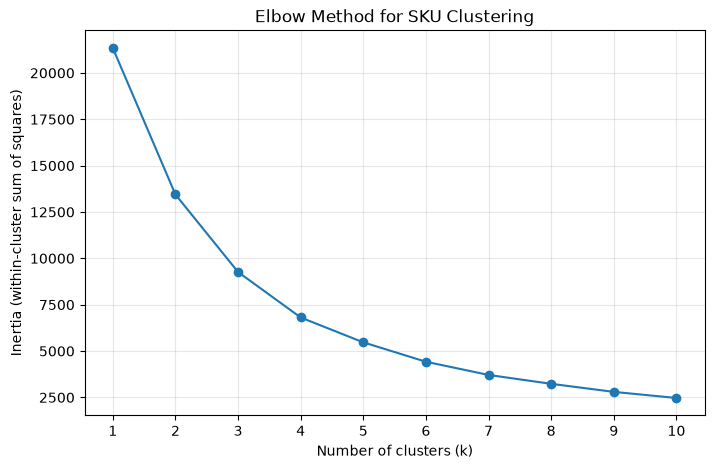

Plot suggests k=3


In [10]:
# option 02: elbow method to choose k

import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# calculate inertia for different numbers of clusters
inertias = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)

    inertias.append(model.inertia_)

# plot the elbow curve
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia (within-cluster sum of squares)')
plt.title('Elbow Method for SKU Clustering')
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.show()
print('Plot suggests k=3')

## Fit k-means

In [11]:
# fit K-means using three clusters
K = 3
kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)

# assign each SKU to its closest cluster centroid
sku_features['cluster'] = kmeans.fit_predict(X_scaled)

## Summarize

In [12]:
# summarize sales characteristics for each cluster
cluster_summary = (
    sku_features.groupby('cluster')
    .agg(
        sku_count=('item_id', 'nunique'),
        avg_daily_units=('avg_daily_units', 'mean'),
        median_daily_units=('median_daily_units', 'mean'),
        std_daily_units=('std_daily_units', 'mean'),
        zero_sales_rate=('zero_sales_rate', 'mean'),
        coefficient_of_variation=('coefficient_of_variation', 'mean')
    )
    .round(3)
)

display(cluster_summary)
print('Next steps:\
\nUnderstand high zero_sales_rate for cluster=0\
\nFurthermore, understand if carrying these items are even worth it, considering their median sales=0\
\nUnderstand which items account for cluster=2; they are massive drivers of units sold,\
\nand they have low variation, which makes them predictable.')

,sku_count,avg_daily_units,median_daily_units,std_daily_units,zero_sales_rate,coefficient_of_variation
cluster,,,,,,
0,1111,2.276,1.407,2.633,0.404,1.244
1,44,18.113,15.364,14.948,0.179,0.886
2,1894,0.369,0.000,0.806,0.788,2.635


Next steps:
Understand high zero_sales_rate for cluster=0
Furthermore, understand if carrying these items are even worth it, considering their median sales=0
Understand which items account for cluster=2; they are massive drivers of units sold,
and they have low variation, which makes them predictable.


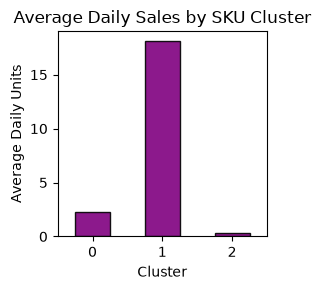

In [13]:
# compare average daily sales across the three clusters
cluster_summary['avg_daily_units'].plot(
    kind='bar',
    figsize=(3, 3),
    color='purple',
    alpha=0.9,
    edgecolor='black',
    title='Average Daily Sales by SKU Cluster',
    xlabel='Cluster',
    ylabel='Average Daily Units'
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

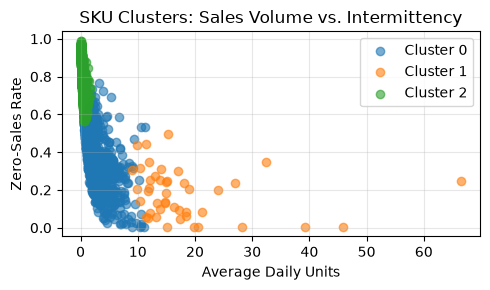

Observe cluster=0's high zero-sales rate


In [14]:
plt.figure(figsize=(5, 3))

for cluster in sorted(sku_features['cluster'].unique()):
    cluster_data = sku_features[sku_features['cluster'] == cluster]

    plt.scatter(
        cluster_data['avg_daily_units'],
        cluster_data['zero_sales_rate'],
        label=f'Cluster {cluster}',
        alpha=0.6
    )

plt.xlabel('Average Daily Units')
plt.ylabel('Zero-Sales Rate')
plt.title('SKU Clusters: Sales Volume vs. Intermittency')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print('Observe cluster=0\'s high zero-sales rate')

# PCA (principal component analysis)
An unsupervised data mining technique.  
Reduces dimensions while preserving variation.

## Choose N=components

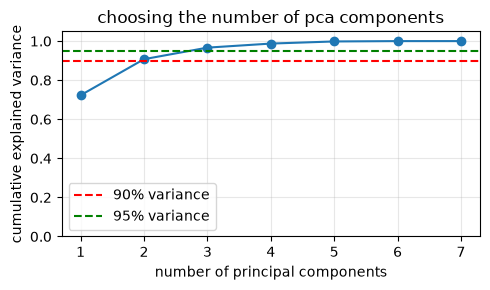

components needed for 90% variance: 2
variance retained: 90.8%


In [15]:
from sklearn.decomposition import PCA

# fit pca using all available components
pca = PCA()
pca.fit(X_scaled)

# calculate the cumulative proportion of variance explained
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

# plot how much variance is retained as components are added
plt.figure(figsize=(5, 3))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='o'
)

# mark common variance-retention thresholds
plt.axhline(y=0.90, linestyle='--', label='90% variance',color='red')
plt.axhline(y=0.95, linestyle='--', label='95% variance',color='green')

plt.xlabel('number of principal components')
plt.ylabel('cumulative explained variance')
plt.title('choosing the number of pca components')
plt.xticks(range(1, len(cumulative_variance) + 1))
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# find the number of components needed to retain at least 90% of variance
n_components_90 = np.argmax(cumulative_variance >= 0.90) + 1

print(f"components needed for 90% variance: {n_components_90}")
print(f"variance retained: {cumulative_variance[n_components_90 - 1]:.1%}")

## Fit the model

In [16]:
# reduce the original features to two principal components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled) # defined above

# store the component scores alongside each sku and its cluster
pca_results = pd.DataFrame({
    'item_id': sku_features['item_id'],
    'cluster': sku_features['cluster'],
    'pc1': X_pca[:, 0],
    'pc2': X_pca[:, 1]
})

# show how much of the original variation each component explains
print(f"pc1 variance explained: {pca.explained_variance_ratio_[0]:.1%}")
print(f"pc2 variance explained: {pca.explained_variance_ratio_[1]:.1%}")
print(f"total variance explained: {pca.explained_variance_ratio_.sum():.1%}")

pc1 variance explained: 72.3%
pc2 variance explained: 18.5%
total variance explained: 90.8%


## Results

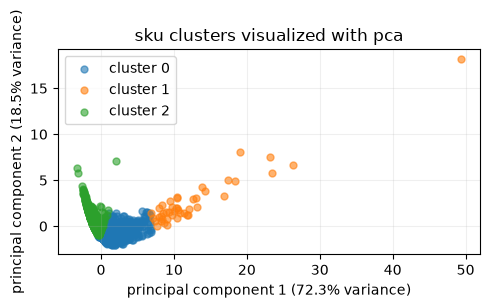

PC1 and PC2 are combinations of the original seven SKU features, 
not individual variables like average sales or sales variability.

PC1 (horizontal axis): captures the greatest amount of variation across the standardized features. 
In this analysis, it primarily reflects sales volume.

PC2 (vertical axis): captures the greatest amount of remaining variation, independent of PC1. 
In this analysis, it primarily reflects demand intermittency and relative variability.

Both components describe how SKUs differ from one another, but along different dimensions. 
PC1 mainly represents sales volume, while PC2 mainly represents how consistent or intermittent sales are.


Notice cluster=1 has the most variation, which is consistent with the k-means clustering output above.


In [17]:
# plot each sku using its two principal component scores
plt.figure(figsize=(5, 3))

for cluster in sorted(pca_results['cluster'].unique()):
    cluster_data = pca_results[pca_results['cluster'] == cluster]

    plt.scatter(
        cluster_data['pc1'],
        cluster_data['pc2'],
        label=f'cluster {cluster}',
        alpha=0.6,
        s=25
    )

plt.title('sku clusters visualized with pca')
plt.xlabel(f"principal component 1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"principal component 2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(
    "PC1 and PC2 are combinations of the original seven SKU features, \n"
    "not individual variables like average sales or sales variability.\n\n"
    "PC1 (horizontal axis): captures the greatest amount of variation "
    "across the standardized features. \nIn this analysis, it primarily "
    "reflects sales volume.\n\n"
    "PC2 (vertical axis): captures the greatest amount of remaining "
    "variation, independent of PC1. \nIn this analysis, it primarily "
    "reflects demand intermittency and relative variability.\n\n"
    "Both components describe how SKUs differ from one another, but "
    "along different dimensions. \nPC1 mainly represents sales volume, "
    "while PC2 mainly represents how consistent or intermittent sales are."
)

print('\n\nNotice cluster=1 has the most variation, which is consistent with the k-means clustering output above.')

In [18]:
# extract the loadings for the first two principal components
loadings = pd.DataFrame(
    pca.components_[:2].T,
    index=feature_columns,
    columns=['pc1', 'pc2']
)

print(loadings.round(3))
print("\nNote that avg_daily_units and total_units contribute almost identically to PC1, \
\nbecause every SKU covers the same number of days. Next step would be remove one variable and re-train.")

                            pc1    pc2
avg_daily_units           0.431  0.143
median_daily_units        0.411  0.158
std_daily_units           0.420  0.158
max_daily_units           0.364  0.248
total_units               0.431  0.143
zero_sales_rate          -0.312  0.575
coefficient_of_variation -0.231  0.719

Note that avg_daily_units and total_units contribute almost identically to PC1, 
because every SKU covers the same number of days. Next step would be remove one variable and re-train.


# Factor analysis
Factor analysis is a statistical method used to describe variability among observed, correlated variables in terms of a potentially lower number of unobserved variables called factors.  


For example, it is possible that variations in six observed variables mainly reflect the variations in two unobserved (underlying) variables. 

Factor analysis is a dimensionality reduction technique, similar to PCA.

## Prep

In [19]:
# select features for factor analysis
factor_columns = [
    'avg_daily_units',
    'median_daily_units',
    'std_daily_units',
    'max_daily_units',
    'zero_sales_rate',
    'coefficient_of_variation'
]

# prepare the feature matrix
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

imputer = SimpleImputer(strategy='median')
scaler = StandardScaler()

X_factor = imputer.fit_transform(sku_features[factor_columns])
X_factor_scaled = scaler.fit_transform(X_factor)

print(f"number of skus: {X_factor_scaled.shape[0]}")
print(f"number of features: {X_factor_scaled.shape[1]}")

number of skus: 3049
number of features: 6


## Choose optimal n components

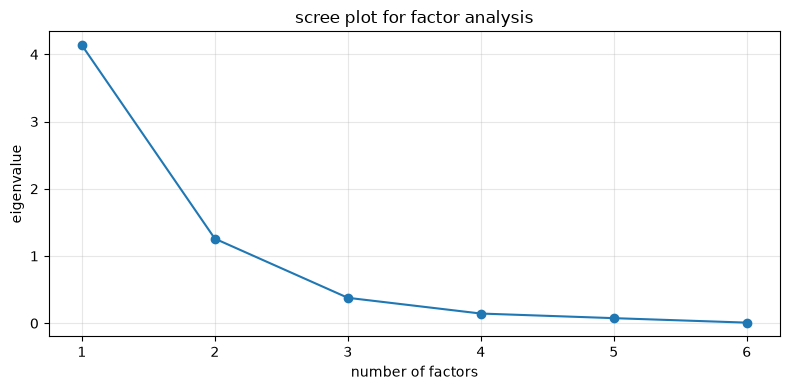

[4.136 1.258 0.378 0.144 0.075 0.009]

The plot suggests n=2, as most of the variation is caught by then.


In [20]:
# calculate eigenvalues of the feature correlation matrix
# Each eigenvalue represents how much variation is associated with a particular mathematical direction
# through the feature space
# eigenvalues from a correlation matrix are a PCA-based heuristic
correlation_matrix = np.corrcoef(X_factor_scaled, rowvar=False)
eigenvalues = np.linalg.eigvalsh(correlation_matrix)[::-1]

# plot the scree plot
plt.figure(figsize=(8, 4))
plt.plot(
    range(1, len(eigenvalues) + 1),
    eigenvalues,
    marker='o'
)
plt.xlabel('number of factors')
plt.ylabel('eigenvalue')
plt.title('scree plot for factor analysis')
plt.xticks(range(1, len(eigenvalues) + 1))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(np.round(eigenvalues, 3))
print('\nThe plot suggests n=2, as most of the variation is caught by then.')

## Fit

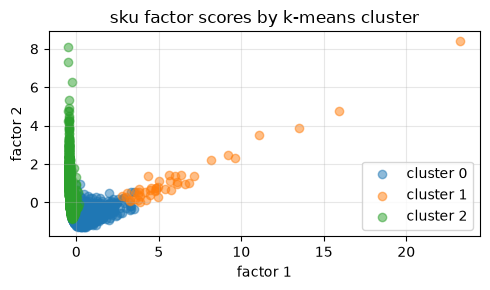

                          factor_1  factor_2
avg_daily_units              1.000     0.003
median_daily_units           0.969     0.045
std_daily_units              0.921    -0.021
max_daily_units              0.756     0.062
zero_sales_rate             -0.564     0.677
coefficient_of_variation    -0.371     0.917

The factor analysis identified two underlying patterns among the SKU features.  
Factor 1 represents demand volume, with high scores associated with higher average and median sales, 
greater absolute variability, and fewer zero-sales days.  
Factor 2 represents demand intermittency, with high scores associated with more zero-sales days and greater relative variability.  
These interpretations are promising, but further model-fit checks are needed to determine whether two factors are optimal.



In [21]:
from sklearn.decomposition import FactorAnalysis

N = 2
# fit a two-factor model
# factor analysis assumes that relationships between observed features can be explained
# partly by a smaller number of unobserved, or latent, factors
fa = FactorAnalysis(n_components=N, random_state=42)
factor_scores = fa.fit_transform(X_factor_scaled)

# inspect how each feature relates to each factor
factor_loadings = pd.DataFrame(
    fa.components_.T,
    index=factor_columns,
    columns=['factor_1', 'factor_2']
)

# create a dataframe of factor scores
factor_scores_df = pd.DataFrame(
    factor_scores,
    columns=['factor_1', 'factor_2']
)

factor_scores_df['item_id'] = sku_features['item_id'].values

# join factor scores to sku features
sku_features = sku_features.merge(
    factor_scores_df,
    on='item_id',
    how='left'
)

# plot factor scores by existing k-means cluster
plt.figure(figsize=(5, 3))

for cluster in sorted(sku_features['cluster'].unique()):
    cluster_data = sku_features[sku_features['cluster'] == cluster]
    plt.scatter(
        cluster_data['factor_1'],
        cluster_data['factor_2'],
        label=f'cluster {cluster}',
        alpha=0.5
    )

plt.xlabel('factor 1')
plt.ylabel('factor 2')
plt.title('sku factor scores by k-means cluster')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(factor_loadings.round(3))

print("""
The factor analysis identified two underlying patterns among the SKU features.  
Factor 1 represents demand volume, with high scores associated with higher average and median sales, \ngreater absolute variability, and fewer zero-sales days.  
Factor 2 represents demand intermittency, with high scores associated with more zero-sales days and greater relative variability.  
These interpretations are promising, but further model-fit checks are needed to determine whether two factors are optimal.
""")

In [22]:
# show skus with the highest scores on each factor
for factor in ['factor_1', 'factor_2']:
    print(f'\ntop skus for {factor}:')
    print(
        sku_features[['item_id', factor]]
        .sort_values(factor, ascending=False)
        .head()
        .to_string(index=False)
    )


top skus for factor_1:
    item_id  factor_1
FOODS_3_090 23.280661
FOODS_3_586 15.892734
FOODS_3_252 13.520066
FOODS_3_120 11.088300
FOODS_3_714  9.622832

top skus for factor_2:
        item_id  factor_2
    FOODS_3_090  8.427377
  HOBBIES_1_026  8.104118
HOUSEHOLD_1_378  7.313691
HOUSEHOLD_1_133  6.257123
    FOODS_3_350  5.343806


In [23]:
print('done')

done
